# Sweep results
Reads `out/*/` (written by `run.py`). Re-run all cells after new runs finish.

In [1]:
import json, glob, os
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

rows, hists = [], {}
for d in sorted(glob.glob("out/*/")):
    name = os.path.basename(d.rstrip("/"))
    if not (os.path.exists(d+"config.json") and os.path.exists(d+"results.json")):
        continue                                   # still running or failed
    cfg = json.load(open(d+"config.json")); res = json.load(open(d+"results.json"))
    if cfg["model"] == "baselines":                # {baseline: {pair: metrics}}
        for bname, per_pair in res.items():
            for pair, m in per_pair.items():
                rows.append({"run": bname, "model": "baseline", "overrides": "", "min": None, "pair": pair, **m})
    else:                                          # {ALL/pair: metrics}
        hists[name] = json.load(open(d+"history.json"))
        for pair, m in res.items():
            rows.append({"run": name, "model": cfg["model"], "overrides": " ".join(cfg["overrides"]),
                         "min": cfg["minutes"], "pair": pair, **m})
df = pd.DataFrame(rows)
print(len(df.run.unique()), "runs loaded")

15 runs loaded


## Pooled (ALL), sorted by switch PR-AUC

In [2]:
cols = ["model","overrides","switch_PR_AUC","dur_macro_F1","switch_P","switch_R","joint_acc","val_ce_sw","val_ce_dur","min"]
a = df[df.pair=="ALL"].set_index("run")[cols]
a["score"] = 0.5*(a.switch_PR_AUC + a.dur_macro_F1)    # same as trainer.select_score
a.sort_values("score", ascending=False)

,model,overrides,switch_PR_AUC,dur_macro_F1,switch_P,switch_R,joint_acc,val_ce_sw,val_ce_dur,min,score
run,,,,,,,,,,,
all_qw4b_8k,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 QWEN_EPO...",0.817,0.622,0.664,0.806,0.908,0.1566,0.8124,395.8,0.7195
all_qwen_8k_dur03,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 QWEN_EPO...",0.806,0.614,0.662,0.789,0.908,0.1601,0.8211,109.8,0.7100
all_qwen_8k_emd0,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 QWEN_EPO...",0.798,0.612,0.654,0.785,0.906,0.1645,0.8241,109.5,0.7050
all_qwen_8k,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 QWEN_EPO...",0.795,0.612,0.651,0.784,0.905,0.1663,0.8236,110.2,0.7035
all_xlmr_8k_win32,xlmr,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 EPOCHS=2...",0.791,0.614,0.634,0.795,0.902,0.1728,0.8174,134.0,0.7025
all_xlmr_8k,xlmr,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 EPOCHS=2",0.793,0.611,0.634,0.795,0.902,0.1722,0.8182,135.4,0.7020
all_qwen_8k_emd1,qwen,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 QWEN_EPO...",0.792,0.611,0.648,0.783,0.905,0.1678,0.8237,111.2,0.7015
all_xlmr_8k_win64,xlmr,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 EPOCHS=2...",0.792,0.611,0.634,0.794,0.902,0.1724,0.8190,136.9,0.7015
all_xlmr_8k_win16,xlmr,"PAIR_SEL=""all"" MAX_CONV_PER_PAIR=8000 EPOCHS=2...",0.786,0.604,0.628,0.793,0.900,0.1760,0.8296,123.7,0.6950


## Per pair

In [3]:
for metric in ["switch_PR_AUC", "dur_macro_F1", "joint_acc"]:
    print("\n==", metric, "==")
    display(df[df.pair!="ALL"].pivot(index="run", columns="pair", values=metric))


== switch_PR_AUC ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B0 never-switch,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
B1 lookup,0.496,0.420,0.413,0.427,0.401,0.438,0.342,0.603,0.400,0.372,0.286,0.319
B2 char-ngram LR,0.606,0.600,0.548,0.585,0.608,0.577,0.705,0.870,0.538,0.536,0.427,0.502
all_qw4b_8k,0.811,0.839,0.790,0.810,0.845,0.795,0.861,0.946,0.769,0.763,0.705,0.820
all_qwen_8k,0.789,0.822,0.762,0.782,0.819,0.772,0.843,0.940,0.745,0.731,0.675,0.796
all_qwen_8k_dur03,0.800,0.831,0.778,0.801,0.831,0.781,0.851,0.946,0.755,0.746,0.689,0.807
all_qwen_8k_dur3,0.770,0.807,0.739,0.750,0.803,0.757,0.827,0.930,0.728,0.705,0.652,0.778
all_qwen_8k_emd0,0.793,0.826,0.766,0.789,0.821,0.774,0.847,0.942,0.748,0.735,0.680,0.799



== dur_macro_F1 ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,0.184,0.173,0.166,0.184,0.225,0.187,0.227,0.183,0.181,0.199,0.178,0.213
B0 never-switch,0.184,0.173,0.166,0.184,0.225,0.187,0.227,0.183,0.181,0.199,0.178,0.213
B1 lookup,0.325,0.267,0.301,0.267,0.225,0.274,0.227,0.326,0.350,0.312,0.331,0.213
B2 char-ngram LR,0.505,0.487,0.493,0.474,0.539,0.465,0.531,0.574,0.524,0.481,0.523,0.469
all_qw4b_8k,0.604,0.595,0.616,0.603,0.616,0.580,0.607,0.624,0.636,0.595,0.637,0.593
all_qwen_8k,0.592,0.590,0.605,0.594,0.600,0.579,0.581,0.619,0.614,0.586,0.627,0.571
all_qwen_8k_dur03,0.594,0.593,0.617,0.605,0.602,0.578,0.576,0.618,0.617,0.587,0.627,0.572
all_qwen_8k_dur3,0.586,0.583,0.604,0.589,0.596,0.577,0.581,0.618,0.616,0.578,0.625,0.573
all_qwen_8k_emd0,0.598,0.594,0.606,0.595,0.598,0.576,0.577,0.618,0.611,0.584,0.627,0.577



== joint_acc ==


pair,ar-en,de-en,es-en,fr-en,hi-en,it-en,ja-en,ko-en,ru-en,vi-en,yue-en,zh-en
run,,,,,,,,,,,,
B0 always-switch,0.050,0.042,0.040,0.044,0.038,0.044,0.035,0.062,0.050,0.049,0.032,0.038
B0 never-switch,0.870,0.880,0.880,0.886,0.924,0.888,0.932,0.837,0.866,0.885,0.911,0.919
B1 lookup,0.684,0.627,0.605,0.608,0.659,0.629,0.877,0.749,0.684,0.810,0.833,0.872
B2 char-ngram LR,0.756,0.774,0.740,0.758,0.790,0.751,0.881,0.865,0.733,0.742,0.773,0.814
all_qw4b_8k,0.878,0.899,0.887,0.896,0.933,0.893,0.950,0.905,0.873,0.887,0.904,0.929
all_qwen_8k,0.874,0.894,0.883,0.890,0.930,0.891,0.947,0.902,0.867,0.880,0.904,0.926
all_qwen_8k_dur03,0.877,0.897,0.887,0.896,0.931,0.893,0.947,0.903,0.870,0.885,0.905,0.928
all_qwen_8k_dur3,0.869,0.891,0.878,0.885,0.927,0.886,0.945,0.900,0.862,0.876,0.901,0.924
all_qwen_8k_emd0,0.876,0.895,0.884,0.892,0.929,0.891,0.947,0.902,0.869,0.882,0.904,0.926


## Training curves (val metrics per epoch, ALL)
Note `val_loss` is not comparable between XLM-R and Qwen3.

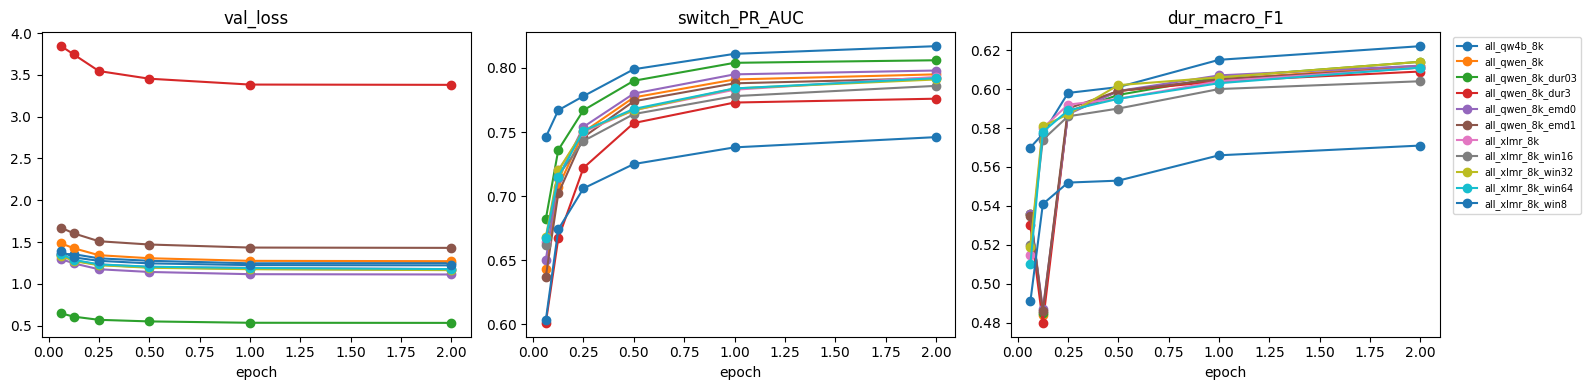

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
def unpack(h):
    # New: {"step","epoch","res"}; Old: one res dict/epoch
    if h and "res" in h[0]:
        return [e["epoch"] for e in h], [e["res"] for e in h]
    return list(range(1, len(h) + 1)), h

for name, h in hists.items():
    ep, rs = unpack(h)
    ax[0].plot(ep, [r["ALL"]["val_loss"] for r in rs], marker="o", label=name)
    ax[1].plot(ep, [r["ALL"]["switch_PR_AUC"] for r in rs], marker="o", label=name)
    ax[2].plot(ep, [r["ALL"]["dur_macro_F1"] for r in rs], marker="o", label=name)
for x, t in zip(ax, ["val_loss", "switch_PR_AUC", "dur_macro_F1"]):
    x.set_title(t); x.set_xlabel("epoch")
ax[2].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()